In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

df = pd.read_csv("loan_approval_dataset.csv")
df.columns = df.columns.str.strip()

## Loan Approval Analysis

This section analyzes the distribution of approved and rejected loan applications.

In [32]:
df['loan_status'].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

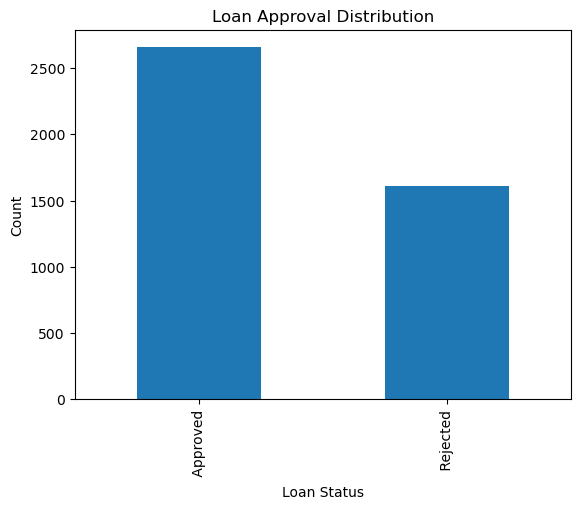

In [33]:
loan_status_counts = df['loan_status'].value_counts()

loan_status_counts.plot(kind='bar')

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Count")

plt.show()

## CIBIL Score Analysis

Credit score is one of the most important factors in lending decisions.

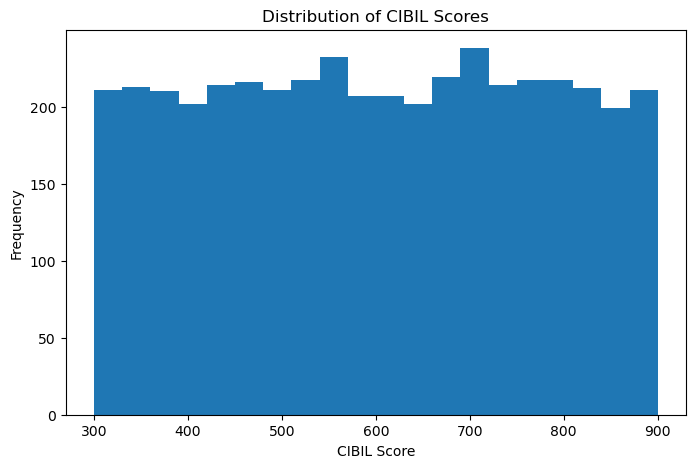

In [34]:
plt.figure(figsize=(8,5))

plt.hist(df['cibil_score'], bins=20)

plt.title("Distribution of CIBIL Scores")
plt.xlabel("CIBIL Score")
plt.ylabel("Frequency")

plt.show()

## Annual Income Analysis

This section evaluates the income distribution of applicants.

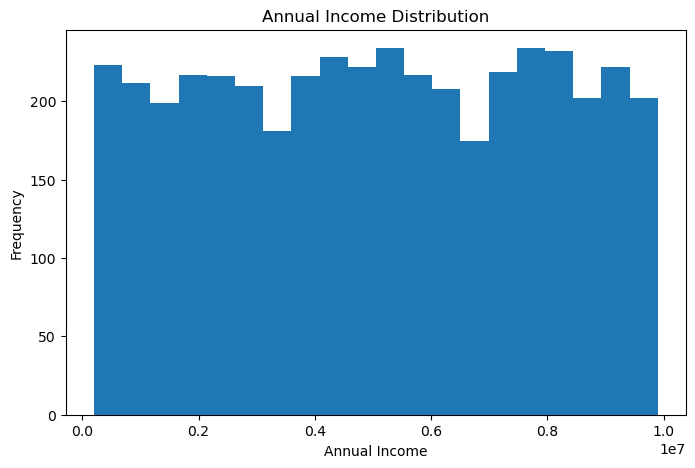

In [35]:
plt.figure(figsize=(8,5))

plt.hist(df['income_annum'], bins=20)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")

plt.show()

## Loan Amount Analysis

Understanding the distribution of requested loan amounts.

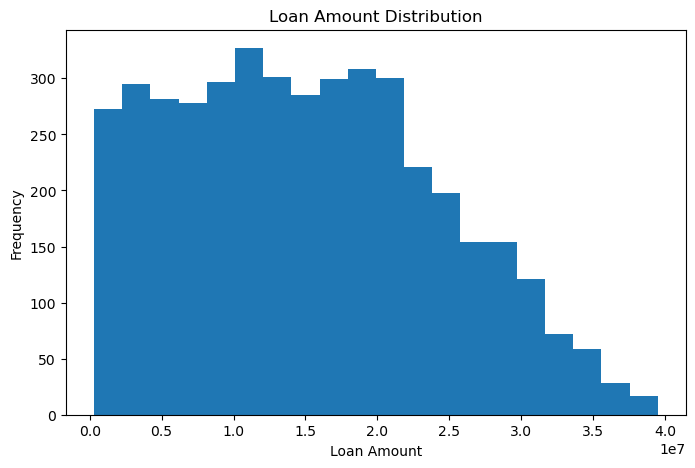

In [36]:
plt.figure(figsize=(8,5))

plt.hist(df['loan_amount'], bins=20)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")

plt.show()

In [37]:
approval_rate = (df['loan_status'].value_counts(normalize=True)*100)

approval_rate

loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64

In [38]:
df.groupby('loan_status')['cibil_score'].mean()

loan_status
Approved    703.461973
Rejected    429.468072
Name: cibil_score, dtype: float64

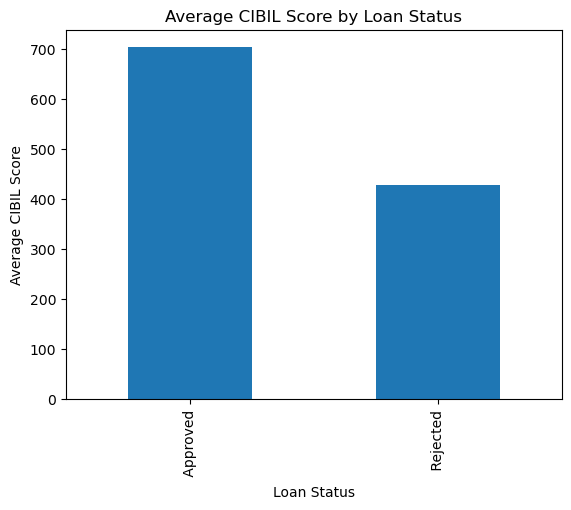

In [39]:
import matplotlib.pyplot as plt

cibil_analysis = df.groupby('loan_status')['cibil_score'].mean()

cibil_analysis.plot(kind='bar')

plt.title("Average CIBIL Score by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Average CIBIL Score")

plt.show()

In [40]:
df.groupby('loan_status')['income_annum'].mean()

loan_status
Approved    5.025904e+06
Rejected    5.113825e+06
Name: income_annum, dtype: float64

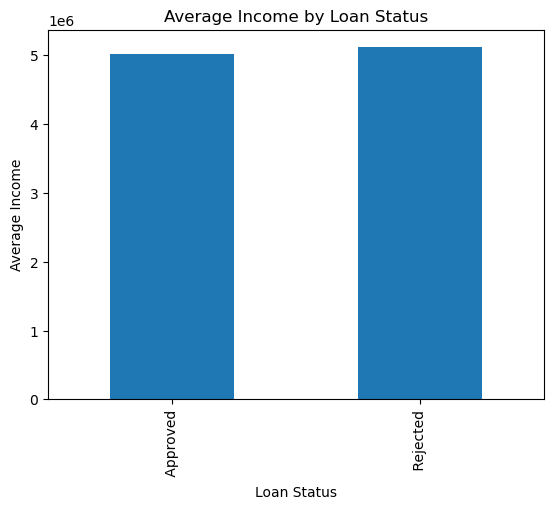

In [41]:
income_analysis = df.groupby('loan_status')['income_annum'].mean()

income_analysis.plot(kind='bar')

plt.title("Average Income by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Average Income")

plt.show()

In [42]:
#Education vs Approval
pd.crosstab(
    df['education'],
    df['loan_status']
)

loan_status,Approved,Rejected
education,,
Graduate,1339,805
Not Graduate,1317,808


In [43]:
#Self Employed vs Approval
pd.crosstab(
    df['self_employed'],
    df['loan_status']
)

loan_status,Approved,Rejected
self_employed,,
No,1318,801
Yes,1338,812


In [44]:
df.groupby('loan_status')['loan_amount'].mean()

loan_status
Approved    1.524725e+07
Rejected    1.494606e+07
Name: loan_amount, dtype: float64

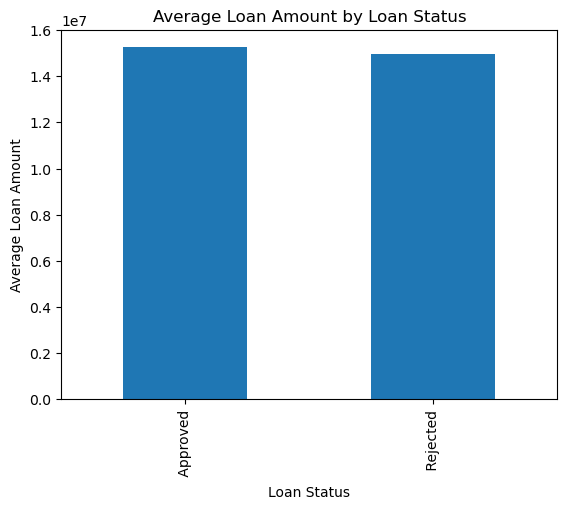

In [45]:
loan_analysis = df.groupby('loan_status')['loan_amount'].mean()

loan_analysis.plot(kind='bar')

plt.title("Average Loan Amount by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Average Loan Amount")

plt.show()

In [46]:
df['total_assets'] = (
    df['residential_assets_value']
    + df['commercial_assets_value']
    + df['luxury_assets_value']
    + df['bank_asset_value']
)

In [47]:
df.groupby('loan_status')['total_assets'].mean()

loan_status
Approved    3.237730e+07
Rejected    3.283112e+07
Name: total_assets, dtype: float64

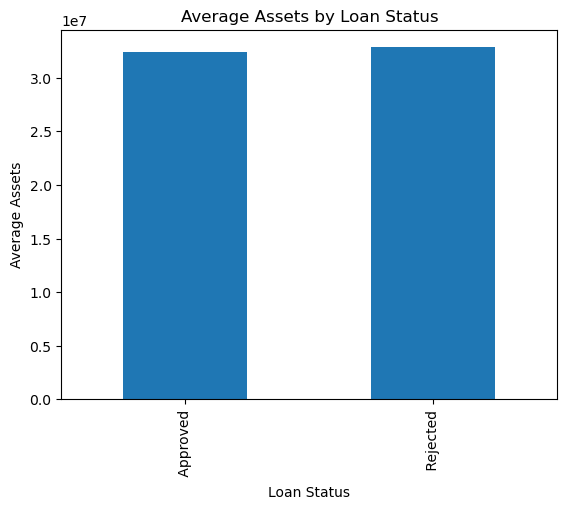

In [48]:
asset_analysis = df.groupby('loan_status')['total_assets'].mean()

asset_analysis.plot(kind='bar')

plt.title("Average Assets by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Average Assets")

plt.show()

In [49]:
df.groupby('loan_status')['cibil_score'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,703.461973,125.249016,300.0,618.0,711.0,803.0,900.0
Rejected,1613.0,429.468072,78.401752,300.0,364.0,429.0,493.0,885.0


In [56]:
conditions = [
    df['cibil_score'] < 550,
    (df['cibil_score'] >= 550) & (df['cibil_score'] < 700),
    df['cibil_score'] >= 700
]

categories = ['High Risk', 'Medium Risk', 'Low Risk']

df['risk_category'] = np.select(
    conditions,
    categories,
    default='Unknown'
)

In [57]:
pd.crosstab(
    df['risk_category'],
    df['loan_status']
)

loan_status,Approved,Rejected
risk_category,,
High Risk,185,1600
Low Risk,1423,7
Medium Risk,1048,6


In [58]:
df.groupby('risk_category')['income_annum'].mean()

risk_category
High Risk      5.113613e+06
Low Risk       4.961399e+06
Medium Risk    5.099431e+06
Name: income_annum, dtype: float64

In [59]:
df.groupby('risk_category')['total_assets'].mean()

risk_category
High Risk      3.298224e+07
Low Risk       3.186622e+07
Medium Risk    3.274070e+07
Name: total_assets, dtype: float64

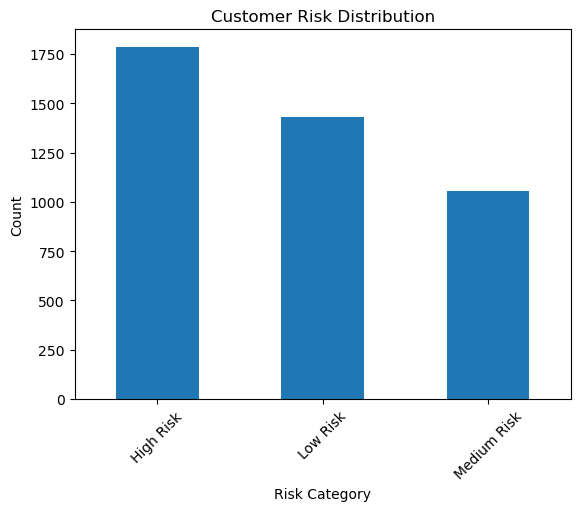

In [60]:
risk_counts = df['risk_category'].value_counts()

risk_counts.plot(kind='bar')

plt.title("Customer Risk Distribution")
plt.xticks(rotation=45)
plt.xlabel("Risk Category")
plt.ylabel("Count")

plt.show()

# Key Findings from Exploratory Data Analysis

Loan approval rate is approximately 62%, while 38% of applications are rejected.

CIBIL score is the strongest factor influencing loan approval decisions.

Applicants with CIBIL scores above 700 have approval rates exceeding 99%.

High-risk applicants (CIBIL < 550) experience rejection rates close to 90%.

Income level has minimal impact on approval decisions.

Asset ownership does not significantly influence loan approval outcomes.

Education level and employment status show little relationship with approval rates.

Creditworthiness is the primary driver of lending decisions in this dataset.